In [2]:
import pandas as pd
import numpy as py
import matplotlib.pyplot as plt
plt.rcParams[ 'font.sans-serif' ] = [ 'SimHei' ]
plt.rcParams[ 'axes.unicode_minus' ] = False

df=pd.read_csv("online_retail.csv")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010/12/1 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010/12/1 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010/12/1 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010/12/1 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010/12/1 8:26,3.39,17850.0,United Kingdom


In [3]:
print(df.info())
print(df.isnull().sum())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB
None
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
            Quantity      UnitPrice     CustomerID
count  541909.000000  541909.000000  406829.000000
mean        9.552250       4.611114   15287.690570
std       218.081158      96.759853    1713.600303

In [4]:
df['InvoiceDate']=pd.to_datetime(df['InvoiceDate'])
print ( '时间范围:' , df[ 'InvoiceDate' ]. min (), '到' , df[ 'InvoiceDate' ]. max ())
print (df['Country'].value_counts().head(10))

时间范围: 2010-12-01 08:26:00 到 2011-12-09 12:50:00
Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64


In [5]:
print ( '总订单数:' , df[ 'InvoiceNo' ].nunique())
print ( '总客户数:' , df[ 'CustomerID' ].nunique())
print ( '总商品数:' , df[ 'StockCode' ].nunique())

总订单数: 25900
总客户数: 4372
总商品数: 4070


In [6]:
print('清洗前:',df.shape)
df=df.dropna(subset=['CustomerID'])
print('清洗后:',df.shape)
print(df.isnull().sum())



清洗前: (541909, 8)
清洗后: (406829, 8)
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [7]:
#退货订单
#看有多少退货
returns=df[df['Quantity']<0]
print('退货订单数:',len(returns))
print(returns.head())
#退货订单的InvoiceNo是不是以C开头，即是否是退货订单
print(returns['InvoiceNo'].str.startswith('C').sum())



退货订单数: 8905
    InvoiceNo StockCode                       Description  Quantity  \
141   C536379         D                          Discount        -1   
154   C536383    35004C   SET OF 3 COLOURED  FLYING DUCKS        -1   
235   C536391     22556    PLASTERS IN TIN CIRCUS PARADE        -12   
236   C536391     21984  PACK OF 12 PINK PAISLEY TISSUES        -24   
237   C536391     21983  PACK OF 12 BLUE PAISLEY TISSUES        -24   

            InvoiceDate  UnitPrice  CustomerID         Country  
141 2010-12-01 09:41:00      27.50     14527.0  United Kingdom  
154 2010-12-01 09:49:00       4.65     15311.0  United Kingdom  
235 2010-12-01 10:24:00       1.65     17548.0  United Kingdom  
236 2010-12-01 10:24:00       0.29     17548.0  United Kingdom  
237 2010-12-01 10:24:00       0.29     17548.0  United Kingdom  
8905


In [8]:
# 只保留正常订单(Quantity>0 且 UnitPrice>0)
df_clean = df[(df[ 'Quantity' ] > 0 ) & (df[ 'UnitPrice' ] > 0 )]
print ( '清洗前:' , df.shape)
print ( '清洗后:' , df_clean.shape)

清洗前: (406829, 8)
清洗后: (397884, 8)


In [9]:
df = df_clean.copy()
print (df.describe())

            Quantity                    InvoiceDate      UnitPrice  \
count  397884.000000                         397884  397884.000000   
mean       12.988238  2011-07-10 23:41:23.511023360       3.116488   
min         1.000000            2010-12-01 08:26:00       0.001000   
25%         2.000000            2011-04-07 11:12:00       1.250000   
50%         6.000000            2011-07-31 14:39:00       1.950000   
75%        12.000000            2011-10-20 14:33:00       3.750000   
max     80995.000000            2011-12-09 12:50:00    8142.750000   
std       179.331775                            NaN      22.097877   

          CustomerID  
count  397884.000000  
mean    15294.423453  
min     12346.000000  
25%     13969.000000  
50%     15159.000000  
75%     16795.000000  
max     18287.000000  
std      1713.141560  


In [10]:
df['Amount']=df['Quantity']*df['UnitPrice']
print('总销售额:',round(df['Amount'].sum(),2))
print('总订单数:',df['InvoiceNo'].nunique())
print('总客户数:',df['CustomerID'].nunique())
print('总商品数:',df['StockCode'].nunique())
print('客单价:',round(df['Amount'].sum()/df['InvoiceDate'].nunique(),2))


总销售额: 8911407.9
总订单数: 18532
总客户数: 4338
总商品数: 3665
客单价: 515.65


Country
United Kingdom    7308391.554
Netherlands        285446.340
EIRE               265545.900
Germany            228867.140
France             209024.050
Australia          138521.310
Spain               61577.110
Switzerland         56443.950
Belgium             41196.340
Sweden              38378.330
Name: Amount, dtype: float64


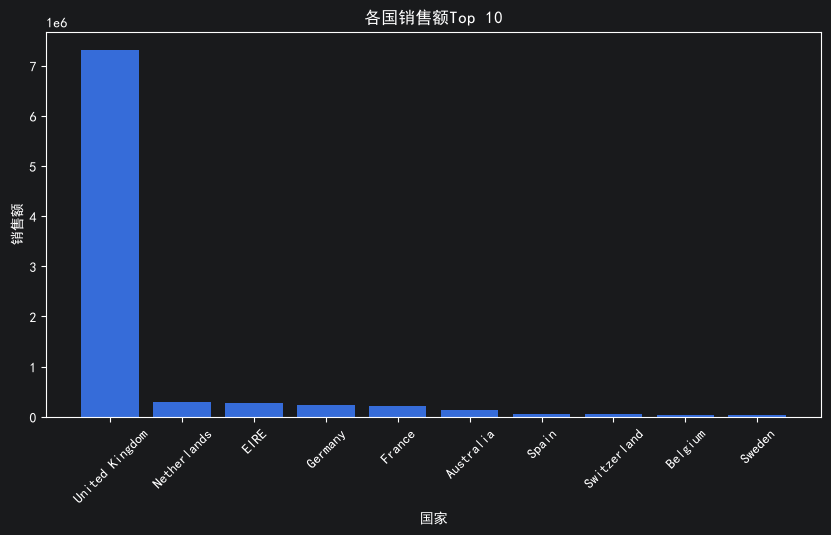

In [11]:
country_sales=df.groupby('Country')['Amount'].sum().sort_values(ascending=False).head(10)
print(country_sales)

#画图
plt.figure(figsize=(10,5))
x=country_sales.index
y=country_sales.values

plt.bar(x,y)

plt.title('各国销售额Top 10')
plt.xlabel('国家')
plt.ylabel('销售额')
plt.xticks(rotation=45)

plt.show()


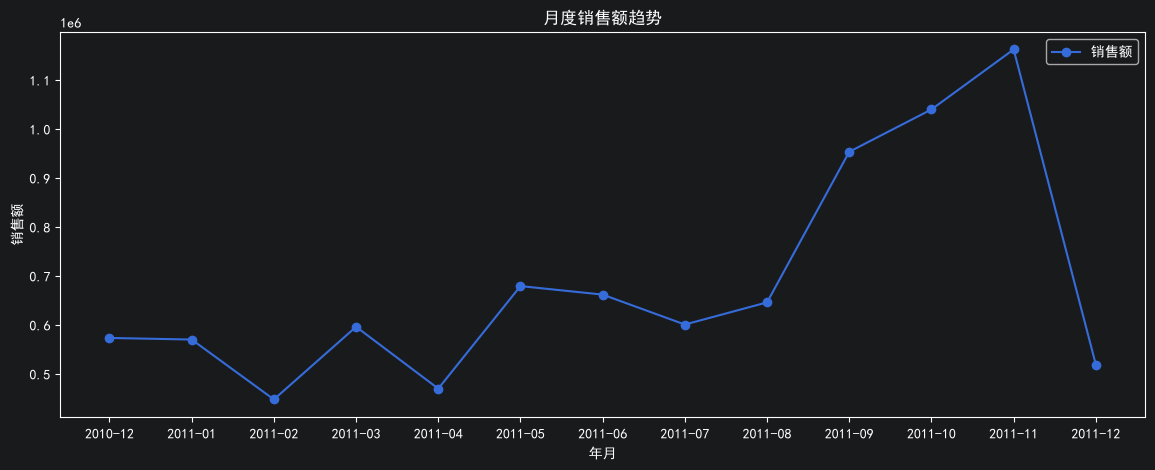

   YearMonth          销售额   订单数   客户数
0    2010-12   572713.890  1400   885
1    2011-01   569445.040   987   741
2    2011-02   447137.350   997   758
3    2011-03   595500.760  1321   974
4    2011-04   469200.361  1149   856
5    2011-05   678594.560  1555  1056
6    2011-06   661213.690  1393   991
7    2011-07   600091.011  1331   949
8    2011-08   645343.900  1280   935
9    2011-09   952838.382  1755  1266
10   2011-10  1039318.790  1929  1364
11   2011-11  1161817.380  2657  1664
12   2011-12   518192.790   778   615


In [23]:
df[ 'YearMonth' ] = df[ 'InvoiceDate' ].dt.strftime( '%Y-%m' )
df[ 'Month' ] = df[ 'InvoiceDate' ].dt.month
df[ 'Hour' ] = df[ 'InvoiceDate' ].dt.hour
df[ 'Weekday' ] = df[ 'InvoiceDate' ].dt.day_name()

monthly = df.groupby( 'YearMonth' ).agg(
    销售额=( 'Amount' , 'sum' ),
    订单数=( 'InvoiceNo' , 'nunique' ),
    客户数=( 'CustomerID' , 'nunique' )
).reset_index()

plt.figure(figsize=( 14 , 5 ))
plt.plot(monthly[ 'YearMonth' ], monthly[ '销售额' ], marker= 'o' , label= '销售额' )
plt.title( '月度销售额趋势' )
plt.xlabel( '年月' )
plt.ylabel( '销售额' )
plt.xticks(rotation= 0 )
plt.legend()
plt.show()
print (monthly)


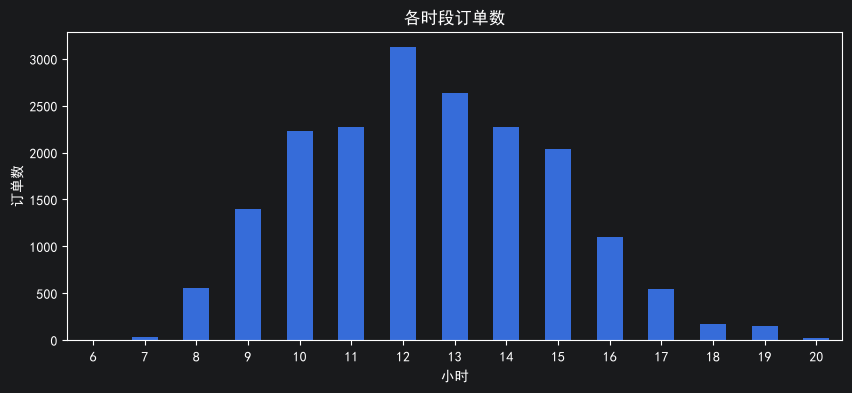

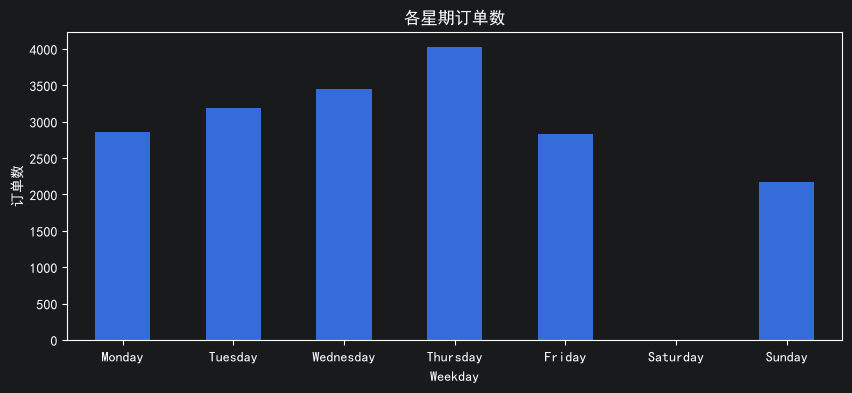

In [26]:
# 每小时订单数
hourly = df.groupby( 'Hour' )[ 'InvoiceNo' ].nunique()
plt.figure(figsize=( 10 , 4 ))
hourly.plot(kind= 'bar' )
plt.title( '各时段订单数' )
plt.xlabel( '小时' )
plt.ylabel( '订单数' )
plt.xticks(rotation= 0 )
plt.show()
# 每星期订单数
weekday_order = [ 'Monday' , 'Tuesday' , 'Wednesday' , 'Thursday' , 'Friday' , 'Saturday' , 'Sunday' ]
weekly = df.groupby( 'Weekday' )[ 'InvoiceNo' ].nunique().reindex(weekday_order)
plt.figure(figsize=( 10 , 4 ))
weekly.plot(kind= 'bar' )
plt.title( '各星期订单数' )
plt.ylabel( '订单数' )
plt.xticks(rotation= 0 )
plt.show()

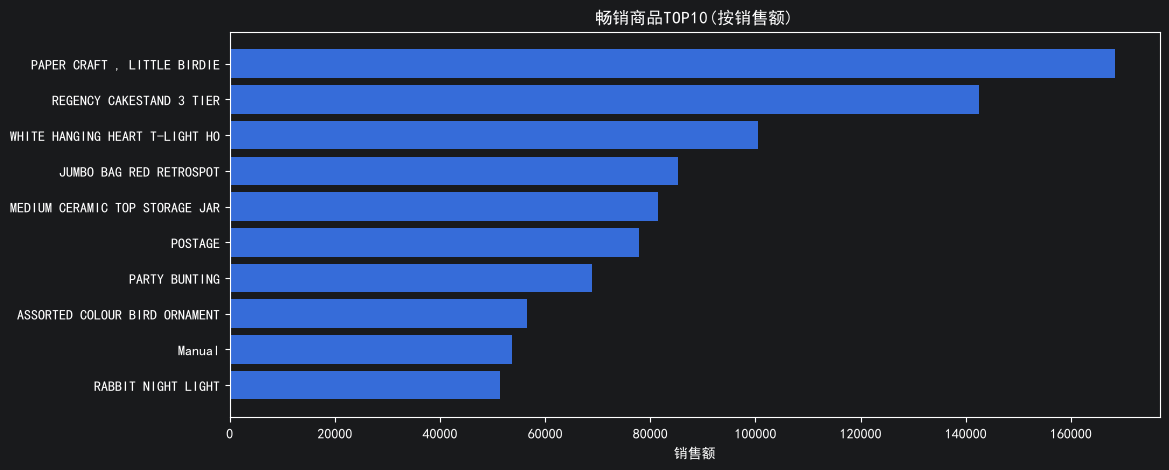

     StockCode                         Description        sum  count
2602     23843         PAPER CRAFT , LITTLE BIRDIE  168469.60      1
1318     22423            REGENCY CAKESTAND 3 TIER  142592.95   1723
3459    85123A  WHITE HANGING HEART T-LIGHT HOLDER  100448.15   2028
3444    85099B             JUMBO BAG RED RETROSPOT   85220.78   1618
2100     23166      MEDIUM CERAMIC TOP STORAGE JAR   81416.73    198
3896      POST                             POSTAGE   77803.96   1099
2799     47566                       PARTY BUNTING   68844.33   1396
3278     84879       ASSORTED COLOUR BIRD ORNAMENT   56580.34   1408
3894         M                              Manual   53779.93    284
2006     23084                  RABBIT NIGHT LIGHT   51346.20    842


In [30]:
# 畅销商品TOP10(按销售额)
top_products = df.groupby([ 'StockCode' , 'Description' ])[ 'Amount' ].agg([ 'sum' , 'count' ]).reset_index()
top_products = top_products.sort_values( 'sum' , ascending= False ).head( 10 )

plt.figure(figsize=( 12 , 5 ))
plt.barh(top_products[ 'Description' ]. str [: 30 ], top_products[ 'sum' ])
plt.title( '畅销商品TOP10(按销售额)' )
plt.xlabel( '销售额' )
plt.gca().invert_yaxis()
plt.show()
print (top_products)

用户类型
一般用户      1906
高价值用户     1319
新用户        665
流失风险用户     448
Name: count, dtype: int64
用户类型
一般用户      0.439
高价值用户     0.304
新用户       0.153
流失风险用户    0.103
Name: proportion, dtype: float64


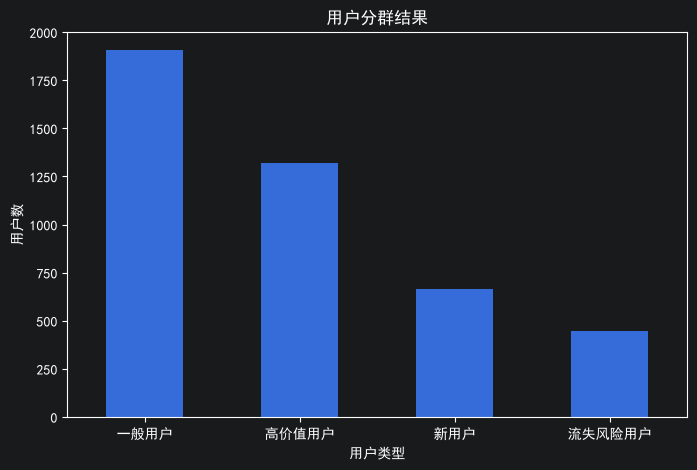

In [31]:
# RFM计算
ref_date = df[ 'InvoiceDate' ]. max () # 参考日期
rfm = df.groupby( 'CustomerID' ).agg(
    R=( 'InvoiceDate' , lambda x: (ref_date - x. max ()).days),
    F=( 'InvoiceNo' , 'nunique' ),
    M=( 'Amount' , 'sum' )
).reset_index()
# 打分(4分位)
rfm[ 'R_score' ] = pd.qcut(rfm[ 'R' ], 4 , labels=[ 4 , 3 , 2 , 1 ])
rfm[ 'F_score' ] = pd.qcut(rfm[ 'F' ].rank(method= 'first' ), 4 , labels=[ 1 , 2 , 3 , 4 ])
rfm[ 'M_score' ] = pd.qcut(rfm[ 'M' ].rank(method= 'first' ), 4 , labels=[ 1 , 2 , 3 , 4 ])
# 用户分群
def classify_user ( row ):
    r, f, m = row[ 'R_score' ], row[ 'F_score' ], row[ 'M_score' ]
    if r>= 3 and f>= 3 and m>= 3 :
        return '高价值用户'
    elif r<= 2 and f>= 3 and m>= 3 :
        return '流失风险用户'
    elif r>= 3 and f<= 2 :
        return '新用户'
    else :
        return '一般用户'
rfm[ '用户类型' ] = rfm.apply(classify_user, axis= 1 )
print (rfm[ '用户类型' ].value_counts())
print (rfm[ '用户类型' ].value_counts(normalize= True ). round ( 3 ))

plt.figure(figsize=( 8 , 5 ))
rfm[ '用户类型' ].value_counts().plot(kind= 'bar' )
plt.title( '用户分群结果' )
plt.ylabel( '用户数' )
plt.xticks(rotation= 0 )
plt.show()

In [ ]:
##项目结论与建议
### 1. 销售季节性明显
# - 11月为销售高峰,销售额远超其他月份
# - 原因:圣诞购物季前备货
# - **建议** :
# 9-10月提前备货,
# 11月加大营销投入;
# 淡季(1-4月)做清仓促销或开发新品类

### 2. 用户购物时段集中
# - 订单高峰在10-15点,说明用户主要在白天购物
# - **建议** :
# 在10-15点推送限时优惠,提升转化;
# 晚上(20-22点)做内容种草,次日转化

### 3. 商品以礼品类为主
# - 畅销品是PAPER CRAFT、REGENCY CAKESTAND等礼品装饰类
# - **建议** :
# 围绕礼品场景做组合销售;
# 开发礼盒套装,提高客单价

### 4. 用户分群结构
# - 高价值用户30.4%:贡献了主要GMV,需重点维护
# - 流失风险用户10.3%:有消费能力但近期未购买,需召回
# - 新用户15.3%:刚购买,需引导复购
# - 一般用户43.9%:需提升活跃度
# - **建议** :
# - 高价值:会员体系+专属优惠
# - 流失风险:发送召回优惠券+个性化推荐
# - 新用户:首单后7天内推送相关商品
# - 一般用户:定期促销激活


## 项目局限
# - 数据仅1年(2010-12到2011-12),无法看年度同比
# - 缺用户画像(年龄、性别),用户分群较粗
# - 缺营销活动数据,无法做活动效果归因
# - RFM的M用消费总额,未考虑利润率